# In-Class Assignment: Reviewing Pandas and exploring data
# Day 5 
# CMSE 202

### <p style="text-align: right;"> &#9989; Dhruti Bhat</p>
#### <p style="text-align: right;"> &#9989; Daniel, Brook, Josh</p>

<img src="https://miro.medium.com/max/819/1*Dss7A8Z-M4x8LD9ccgw7pQ.png" alt="Stylized pandas library logo" width="500px">

## Goals for today's In-class assignment 

1. Make sure that everyone remembers how to do the basics with Pandas.
2. Do a little data analysis with an existing dataset, including considering its provenance and limits.
3. Make some simple visualizations of the data.

### Assignment instructions

Work through the notebook making sure to write all necessary code and answer any questions.

**This assignment is due by the end of class,** and should be uploaded into the appropriate "In-Class assignments" submission folder.  Submission instructions can be found at the end of the notebook.

### How this connects to the course learning goals

Beyond today's specific goals above, this assignment builds toward these **course-level learning goals** (see the syllabus, or the Day 1 notebook, for the full CLG 1-7 list):

- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll load a real dataset, explore it with pandas, and visualize it to find patterns.
- **CLG 2 - Identify and use pre-existing tools and libraries:** you'll use pandas and matplotlib, and practice searching documentation for unfamiliar functions.
- **CLG 1 - Write programs to solve problems:** you'll write code to separate the iris species with Boolean masks, and read/use plain-Python file-reading code.
- **CLG 6 - Work in diverse groups:** you'll discuss concepts and work through the exploration with your table group.

## Agenda for today:

1. [Review of pre-class assignment](#review)
2. [Loading and exploring a dataset](#loading)
3. [Visualizing your data](#visualizing)
4. [What if we didn't have Pandas?](#no-pandas)
5. [Experimenting with generative AI](#generative)

### Useful imports (make sure to execute this cell!)
Let's get a few of our imports out of the way. If you find others you need to add, consider coming back and putting them here.

In [1]:
# necessary imports for this notebook
import pandas as pd
from pandas.plotting import scatter_matrix

----
<a id="review"></a>
## 1. Review of pre-class assignment

Did anyone have any specific issues with the pre-class assignment?

Let's take a moment to highlight some key concepts. **Discuss with your table** the following prompts and write down a brief definition of each of these concepts.

**If you don't feel like you have good working definitions yet, try doing a quick internet search to see if you can find a definition that makes sense to you.**

&#9989; **Question 1:** What are the features of a Pandas Series?

<font size=+3>&#9998;</font> Do This -  Write your disussion notes here.

&#9989; **Question 2:** What are the differences between a DataFrame and a Series?

<font size=+3>&#9998;</font> Do This -  Write your disussion notes here.

- - -

## A note on the history of the Iris dataset

This notebook uses a small, widely reused collection of flower measurements often called the **Iris dataset** and is sometimes referred to as "Fisher's iris data." Knowing where a dataset comes from is part of responsible data work.

The measurements were collected by botanist **Edgar Anderson**, who studied irises from the Gaspé Peninsula. Statistician **Ronald A. Fisher** later used these data in a 1936 paper to demonstrate how multiple measurements can help distinguish biological groups -- a foundational example of multivariate classification. For that reason, the dataset is frequently associated with Fisher, even though he did not collect the measurements.

Fisher's paper was published in the *Annals of Eugenics*. Eugenics was a harmful movement that used distorted ideas about heredity, classification, and social value to support prejudice and discrimination against racial, ethnic, and disabled groups. This history is relevant because statistical and computational methods do not emerge outside of social institutions and values.

The data we use here are measurements of iris flowers, not human data, and our purpose is to practice reading, exploring, visualizing, and reasoning about a small dataset. We can use this familiar example while being accurate about its provenance and recognizing its limits. In particular, it is a very small, unusually clean "toy" dataset -- not a stand-in for the messiness, uncertainty, and potential consequences of most real-world data work.

You may encounter this dataset many times in statistics, machine learning, and data science. When you do, remember to ask: Who collected the data? Who is credited for it? What was the historical setting? What does the dataset leave out? Those questions are part of doing careful, ethical computational work.

**Sources for this note:** Edgar Anderson (1935), *The irises of the Gaspé Peninsula*; R. A. Fisher (1936), "The Use of Multiple Measurements in Taxonomic Problems," *Annals of Eugenics*, 7, 179-188; R's documentation, "Edgar Anderson's Iris Data."

### Brief reflection: provenance and use

&#9989; **Question:** In 2-4 sentences, explain why it matters to distinguish between the person who collected a dataset and the person who later analyzed or popularized it. Then name one limitation of using a small, clean toy dataset to learn about real-world classification.

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your response. Focus on accurate attribution and on what a toy dataset can and cannot show us.

---
<a id="loading"></a>
## 2. Loading and exploring a dataset

Though you review how one can build a DataFrame by hand in your pre-class assignment, the goal is typically to read some sort of preexisting data **into** a DataFrame so we can work with it. 

Pandas is pretty flexible about reading in data and can read in a [variety of formats](https://pandas.pydata.org/pandas-docs/stable/user_guide/io.html). However, it sometimes needs a little help. Let's start with a small "toy" dataset, commonly called the Iris dataset (or the Anderson's iris dataset; as discussed in the historical note above). 

A toy dataset is often one that has a particularly convenient set of features or a manageable size, making it useful for learning new data-analysis techniques or testing code. This lets us focus on code and analytical methods without getting too caught up in data wrangling. However, data wrangling is an authentic part of meaningful data analysis because real data are often messy, incomplete, and shaped by the circumstances in which they were collected. The Iris dataset is useful for practice, but its small size and clean structure mean that it should not be treated as representative of most real-world classification problems. 

Although you will be working with a toy dataset today, you may still have to do a bit of wrangling along the way.

### 2.1 Getting used to looking for useful information on the internet

Another authentic part of working as a computational professional is getting comfortable with searching for help on the internet when you get stuck or run into something that is unfamiliar to you. The Python data analysis/computional modeling world can be complicated and is ever-evolving. There is also a large number of publicly available toolsets with varying levels of complexity and nuance. Through practice and experience, we become better computational folks by learning how to search for better, more efficient, clearer ways to do things. 

#### The Iris data

The iris data set is pretty straight forward (see the historical note above if you haven't reviewed it yet), especially if someone has done all of the data wrangling and cleaning for you. To make it a little more interesting we provide it in a raw form that you might encounter with other data.

**&#9989; Do This:**  To get started, **you'll need to download the following two files** (remember, you can use `curl` for this!):

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/iris.data`

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/iris.names`

Once you've done so, you should have access to the following : `iris.data` and `iris.names`. Open them both and discuss what you see. This is a good opportunity to use you favorite text editor or use something new. Feel free to ask your group members or instructors what they prefer to use.

&#9989; **Question 3**: Describe the data and the information in the names file. What characteristics and documentation are provided there? You may also consult the source links in the historical note above or other credible documentation.

<font size=+3>&#9998;</font> the names file includes information about when it was last updated and some sources and publications. it also has some statistics about the sepal length and width and the petal lenght and width.

###  2.2 Reading in a file

Pandas supports a number of file formats, but one of the most common is the one provided by the `read_csv` function. Typically, the phrase **csv** stands for "comma separated values", a text file format that excel and other spread sheets use. In a typical csv file, each line represents a line in a spreadsheet and each cell value is separated from the next by a comma.

However, you can use other separators as well. Look at the [documentation for `read_csv`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html).

**&#9989; Do This:** Read the ```iris.data``` file into your notebook **and assign appropriate column headers**. Display the DataFrame to make sure it looks reasonable.

In [14]:
# replace this cell with code to read in the iris.data file with column headers. Use appropriate headers!
iris = pd.read_csv("iris.data", sep=r"\s+",
    header=None,
    names=["sepal_length", "sepal_width", "petal_length", "petal_width", "class"]
)

iris

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


### 2.3 Describing your data

The `.describe()` methods tells you about the data, which can be especially useful for large datasets where you want to understand the distribution of your data and get a quick overview of its main characteristics.

As a side note, if the data is too big to see when displayed (height and width) you can use the two options below to control the display of the data. You can change the values to suit your needs. 

In [17]:
# expand what is shown (rows and cols) by pandas, any time you change default options -- be thoughtful about your choices!
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_columns', 400)

**&#9989; Do This:** Run the `.describe()` method on the data you read in. If you think about how you might **classify** the species contained in the dataset based on the four available features, can you discern anything helpful? Put your answer in the cell below.

In [16]:
# Put your code here
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


<font size=+3>&#9998;</font> since the values of the lengths and widths vary significantly between each flower it is useful to classify these flowers using this infromation

### 2.4 Grouping your data
You can perform operations to group elements using the `.groupby()` method. The result of the use of `.groupby` is a `GroupBy` object. If you were to print it you see only the class instance name as nothing is computed until an operation is performed on the groups, much like other iterators. However, you can use a method like `.describe()` on the result of a `.groupby()` call. If you haven't used this before, you may need to consult the [documentation for `.groupby()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html) 

**&#9989; Do This:** Make a GroupBy object using the iris DataFrame and **group by the class/species of the data**. Then run `.describe()` on the group result. Now take a look at the data from the group. Thinking again about classification, **do you see any data features you could use to classify the data when you look at it this way?**

In [18]:
# Put your code here
iris.groupby("class").describe()
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


<font size=+3>&#9998;</font> groupby makes the differences between the values of each flower easier to observe and compare the statistics.

-----
<a id="visualizing"></a>
## 3 Visualizing your data

We are often limited in understanding our data because it is complex, has many features, or is quite large. In these situations, visualizations (plots, charts, and graphs) can help represent our data in ways that help us gain greater insight into the trends, features, and classes we want to understand.

### 3.1 Making a scatter matrix

Rather than just looking at the raw values or exploring basic statistical values for our data, it would be better if we were to visualize the differences. Since the number of features is small, we can use a plotting feature of Pandas called `scatter_matrix()`. Did you notice that we imported `scatter_matrix` at the start of this notebook?

**&#9989; Do This:** Try calling the `scatter_matrix` function on your dataframe. Use a `marker` that you prefer. Look up the documentation for `scatter_matrix` on the Pandas website for more information! You may need to make the figure bigger to get a good look at it.

**Note**: There is a similar sort of plot that can be made with the [seaborn](https://seaborn.pydata.org/index.html) package, which you may have seen before. If so, do you remember what it is?

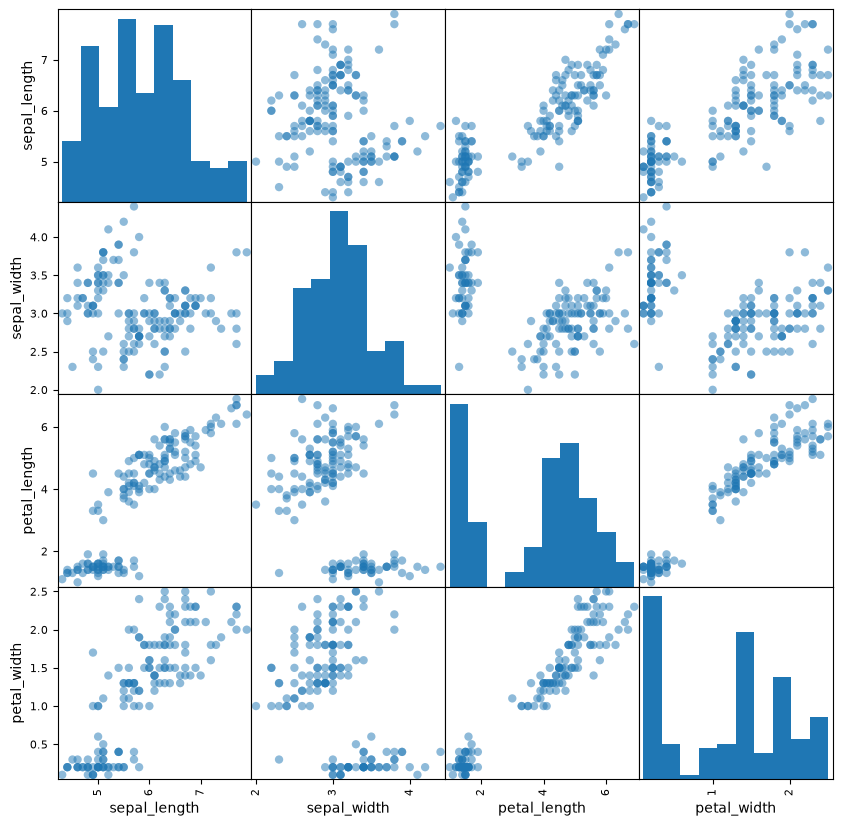

In [20]:
# your code here
from pandas.plotting import scatter_matrix

scatter_matrix(iris, marker="o", figsize=(10, 10))
plt.show()

&#9989; **Question 4**: Does this visualization help you to determine the features that might be useful for classification? Why or why not?

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your answer to the above question!  (double-click on this text to edit this cell, and hit shift+enter to save the text). **Practice using appropriate Markdown formating to make your answer's easy to read.**

### 3.2 Color coding your data

The default scatter matrix probably isn't as helpful as we might hope as it's impossible to tell which points on the plot represent our classes/sepcies.

We could really use a separate color indication for each dot so we can tell the species apart. Essentially, we need to create an array such that, for each observation in the DataFrame, we can assign a color value to associate it with the appropriate species. It could be just an integer, or it could be one of the standard colors such as "red".

**&#9989; Do This:** Create a new list, array, or Pandas Series object that maps each species to a particular color. Then recreate the scatter matrix using the `c` argument to give the points in the plot different colors.

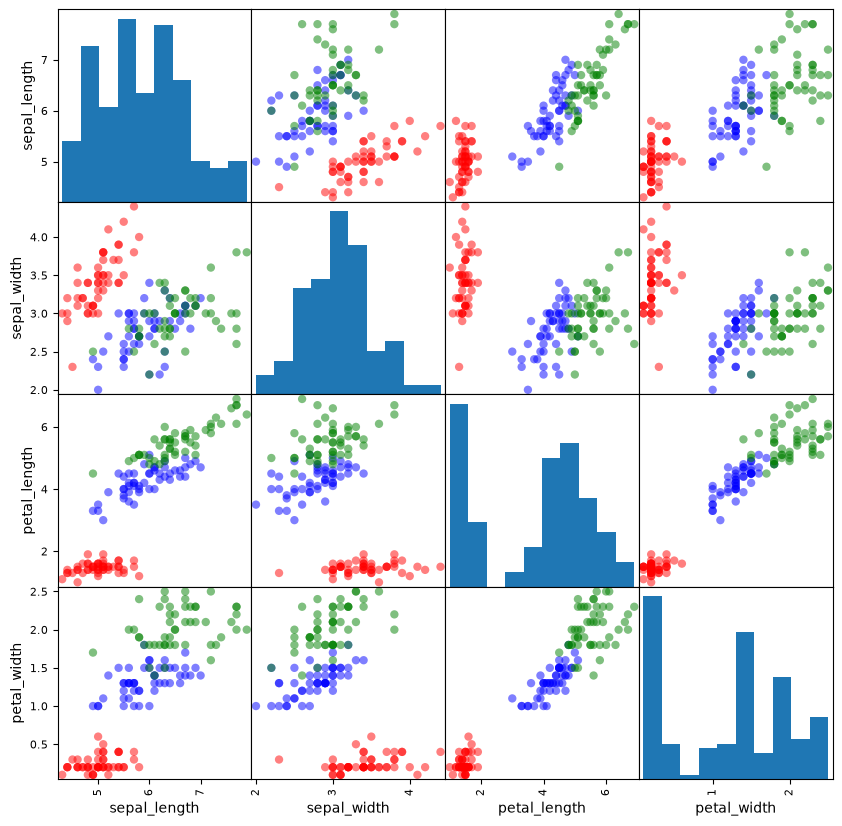

In [21]:
# Put your code here
colors = iris["class"].map({
    "Iris-setosa": "red",
    "Iris-versicolor": "blue",
    "Iris-virginica": "green"
})

scatter_matrix(
    iris.drop(columns=["class"]),
    marker="o",
    figsize=(10, 10),
    c=colors
)

plt.show()

Hope you got something that's a little more useful! OK, how do we read this now?
* The diagonal shows the distribution of the four  numeric variables of our example data.
* In the other cells of the plot matrix, we have the scatterplots (i.e. correlation plot) of each variable combination of our dataframe. 

&#9989; **Question 5**: Are you better able to discern features that might be useful in classfying irises? What can you say about the features of each iris species? Can you separate one species easily? If so, using which feature(s)?

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your answer to the above question!  (double-click on this text to edit this cell, and hit shift+enter to save the text). **Practice using appropriate Markdown formating to make your answer's easy to read.**

### 3.3 Separating species of irises

Now we will use the feature(s) you found above to try to separate iris species. In future parts of the course, we may explore how to do this using models, but for now, you will try to do this by slicing the DataFrame.

**&#9989; Do This:** One of these species is obviously easier to separate than the others. Can you use a Boolean mask on the dataframe and isolate that one species **using the features and *not the species label***? Try to do so below and confirm that you were successful.

In [23]:
# Put your code here
setosa_mask = iris["petal_length"] < 2.5

setosa = iris[setosa_mask]
setosa



,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


**&#9989; Do This:** Can you write a sequence of Boolean masks that separate the other two as well? Are these as effective as the first? Can you think of anything you might do to improve the separation?

In [25]:
# Put your code here
versicolor_mask = (iris["petal_length"] >= 2.5) & (iris["petal_length"] < 5.0)

virginica_mask = iris["petal_length"] >= 5.0

versicolor = iris[versicolor_mask]
virginica = iris[virginica_mask]

versicolor["class"].value_counts()
virginica["class"].value_counts()

class
Iris-virginica     44
Iris-versicolor     2
Name: count, dtype: int64

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your answer. How effective your Boolean mask separation of the 3 species? Any ideas for improvements?

---
<a id="no-pandas"></a>
## 4 What if we didn't have Pandas to read in this data?

While Pandas makes life pretty easy for reading in csv and other file formats, all of this functionality is built on top of the standard Python capability. Python can natively open and read files lines by line, but working with files in this context might not be something you're familiar with. For this part of the assignment, you're going to explore how you can use **just Python** without any special packages to read in the iris data.

### 4.1 Code review: Loading the iris data with basic Python

**&#9989; Do This:**  To get started, **you'll need to download the following file**:

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/code_samples/my_pandas.py`

**&#9989; Do This:** Once you have the file downloaded and in the same location as this notebook **open the file and read through it carefully**. As you read the file **add comments to the lines marked with `#` to explain what you understand the code to be doing**. 

There may be bits of Python code that you've not encounted before so make sure to **talk with your group** and **search for information on the internet** as you try to make sense of the code!

Jot down some of the things you learned or struggled you had in the cell below.

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and make note of anything new you learned from reading through the code or highlight anything you don't feel like you understand.

### 4.2 Using the code: importing the functions and reading in the data

Now that you have the hand-made functions for reading in the iris data, we're going to practice **importing functions from script and then using them in your notebook**.

The technique for doing this is the following:

``` python
from [PACKAGENAME] import [FUNCTION]
```
Where "PACKAGENAME" is the name of the script but without the ".py" part. So for `my_pandas.py`, the PACKAGENAME would be `my_pandas`. Then the FUNCTION is the name of the function from the script that you want to import, e.g. `my_pandas_idx`.

**We'll using this functionality in future assignments, so make sure you feel comfortable with this idea.**

**&#9989; Do This:** Import the `my_pandas` function and the `my_pandas_idx` function (you can do this on one line, check to see if anyone one in your group knows how). Then, **use these two functions to first read in the data and then extract just the second column from the data**.

Once you've done this, **print the first three rows of the iris data and all of the second column.**

In [ ]:
# Put your code here


---
<a id="generative"></a>
## 5. Experimenting with generative AI

In this part of the assignment we're going to revisit using generative AI tools with **HiTA** (which you were formally introduced to last class). The task: see whether an AI assistant can help you develop code that takes the first four columns of the Iris dataset and predicts the species -- ideally doing better than the manual separation you worked out in Section 3.3 -- and then think critically about how well it did.

The goal of this section is to **critically evaluate an AI assistant as a tool for generating code** -- where it helps, where it falls short, and how to use it *without compromising your own learning*. (You may or may not fully succeed in coaxing a useful, understandable classifier out of the tool -- that outcome is itself worth reflecting on.)

> **Using AI is optional in this course.** As stated in the course's generative AI policy, no assignment *requires* you to use AI tools, and choosing not to -- for ethical, environmental, personal, or any other reasons -- is completely valid. There are two ways to complete this section, and **both reach the same goal and involve a comparable amount of work**:
> * **Option A -- Use HiTA:** try the tool on the classification task and reflect on the experience.
> * **Option B -- AI-free alternative:** improve your own species-separation approach from Section 3.3, and critically evaluate a sample HiTA conversation.
>
> Choose whichever you're comfortable with, and complete **only that option's** work and reflection below. You do **not** need to explain your choice.

### Option A: Using HiTA

**&#9989; Do This:** Use HiTA to help you develop code that takes the first four columns of the Iris dataset and predicts the species -- aiming to do better than the manual separation you worked out in Section 3.3. You can use HiTA's general chat interface, or open the Day 05 ICA notebook and chat with HiTA there (**which is the recommended approach** for this type of task).

As you work with it, keep these in mind:
* **Aim for code you understand and can explain.** Avoid code that uses advanced techniques you don't fully grasp -- if HiTA suggests something unfamiliar, ask it to explain, or steer it toward simpler approaches (for example, threshold-based rules rather than a machine-learning classifier).
* You should be able to **run the code and get a reasonable result.** If you don't, try modifying your prompt and asking again.

Put your AI-assisted code in the cell below, and **cite the tool and the essential prompt(s) you used** -- see the course generative AI policy for why citing your prompts matters.

In [ ]:
# Put your AI-assisted species identification code here
# Make sure to cite the tool you use and the key prompt(s) you used to get things working


# Example Citation:
# Code developed with assistance from HiTA (the CMSE 202 AI assistant), accessed at https://app.hita.ai
# Key prompts: {'help me write python code that uses the first four columns of the iris data to predict the species';
#               'can we do this with simple threshold rules instead of a machine-learning classifier?'}


**&#9989; Reflect:** In the cell below, describe your experience:
* Did HiTA produce code you could understand and explain? Did it reach for techniques beyond what you've learned so far?
* How well did the generated classifier work compared to your manual approach from Section 3.3?
* What do you see as the **benefits** and the **limitations** of using an AI assistant for a task like this?

<font size=+3>&#9998;</font> Do This - If you chose **Option A**, erase the contents of this cell and record your reflection here. (double-click to edit, shift+enter to save)

### Option B: An AI-free alternative

If you'd prefer not to use AI, complete this section using the resources around you instead.

**&#9989; Do This:** Revisit your species-separation work from Section 3.3 and try to **improve or extend it** -- for example, can you separate the species more accurately, or better handle the overlap between *versicolor* and *virginica*? Use the **course materials, the dataset itself, your group members, and the instructional team**. Put your improved code in the cell below.

**Note:** If you can't immediately identify a way to improve your approach, you can instead focus on **analyzing the limitations of your original approach** and thinking about how you might address them. If you do this, describe your analysis and ideas for improvement as comments in the cell below.

In [ ]:
# Put your improved (non-AI) species-separation code here.


**&#9989; Do This:** To reflect on AI as a code-generation tool *without using one*, read the sample HiTA conversation shown below, then use the questions that follow it to evaluate the tool critically.

#### Sample HiTA conversation

The exchange below is a **real conversation between an instructor and HiTA** working on today's task -- improving the Boolean-mask separation of the three iris species from Section 3.3. The screenshot shows HiTA in its **focused-content mode**, where the assignment notebook is rendered right alongside the chat; the **full text of the conversation follows** so you can read all of it.

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/hita-sample-conversation-day05.jpg" alt="Screenshot of HiTA in its focused-content mode: the HiTA chat panel is on the left and this Day 05 in-class assignment notebook (Section 3.3) is rendered alongside it on the right. In the chat, the student asks for a more effective way to separate the iris species in Section 3.3, and HiTA responds with guiding hints about combining petal-length and petal-width thresholds with the bitwise & operator and follow-up questions rather than a finished classifier, with expandable Sources citations below each reply" width=900>

> **TRANSCRIPT OF SAMPLE HiTA CONVERSATION**
>
> **You:** I need your help trying to find a more effective way to do Part 3.3 of this assignment.
>>
>> **HiTA:** To help you improve the separation of the iris species using Boolean masks, consider this hint: Look closely at your scatter matrix or pair plots from Section 3, specifically comparing **petal length** and **petal width**. You can combine multiple conditions using the bitwise AND operator (`&`) in Pandas—for instance, checking if a feature is greater than one threshold *and* another feature is less than a second threshold—to isolate regions where the overlapping species are best separated. Which specific feature boundaries or combinations have you tried using so far to separate *versicolor* and *virginica*?
>>
> **You:** This was my solution:
>
> ```python
> setosa = df[df["petal_w"] <= 0.9]
> not_setosa = df[df["petal_w"] > 1.0]
> versi = not_setosa[not_setosa["petal_l"] < 5]
> versi.describe()
> ```
>
> Can I do anything more effectively than this?
>>
>> **HiTA:** You can combine multiple conditions directly in a single line using the bitwise `&` operator (remembering to wrap each comparison condition in parentheses `()`) rather than creating intermediate DataFrames. How might you define a complementary mask using your feature thresholds to isolate the third species (*virginica*)?
>>
> **You:** I'm not entirely sure how best to separate out virginica, could you try to explain an option for that?
>>
>> **HiTA:** Since you isolated *versicolor* by checking where petal length was below a certain threshold (after excluding *setosa*), you can apply the opposite threshold rule—such as requiring petal length or petal width to be greater than or equal to that boundary value—to capture *virginica*. What threshold condition on `petal_l` or `petal_w` naturally captures the remaining larger measurements without including *versicolor*?
>>
> **You:** Could you provide some example code that I might work with to do this?
>>
>> **HiTA:** Here is a general example demonstrating how to slice a dataset into three groups using multiple combined conditions with Boolean masks on a different dataset:
>>
>> ```python
>> # Example: Classifying vehicles by weight and horsepower thresholds
>> compact    = df[df["weight"] < 2500]
>> midsize    = df[(df["weight"] >= 2500) & (df["horsepower"] < 200)]
>> heavy_duty = df[(df["weight"] >= 2500) & (df["horsepower"] >= 200)]
>> ```
>>
>> Notice how each condition inside the bitwise operator `&` is surrounded by parentheses `()` to ensure Pandas evaluates the comparisons in the correct order. How might you adapt this structure to select the *virginica* group using your chosen `petal_l` and `petal_w` boundaries?
>>
> **You:** what exactly is the bitwise operator doing?
>>
>> **HiTA:** In Python and Pandas, the bitwise operator (such as `&` for AND or `|` for OR) performs an **element-by-element (vectorized)** comparison across two series or arrays of boolean values (`True`/`False`), rather than evaluating the entire object at once. For example, when you write:
>>
>> ```python
>> (df["petal_w"] > 1.0) & (df["petal_l"] >= 5.0)
>> ```
>>
>> 1. `(df["petal_w"] > 1.0)` produces a Series of `True` and `False` values for each row.
>> 2. `(df["petal_l"] >= 5.0)` produces a second Series of `True` and `False` values for each row.
>> 3. The `&` operator compares each corresponding pair of values row by row: it returns `True` only for rows where **both** conditions are `True`, and `False` otherwise.
>>
>> Standard Python `and` doesn't know how to compare two entire Series elementwise (it expects a single truth value for the whole object), which is why Pandas relies on the bitwise `&` operator for combining multiple column conditions. Does this distinction between elementwise comparison and standard boolean evaluation make sense?
>>
> **You:** Not really, could you provide an analogy that might help me understand this?
>>
>> **HiTA:** Imagine a teacher checking two separate checklists for a whole classroom of students:
>> 1. **Checklist 1:** Does the student have their textbook? (Produces a list of Yes/No for each student in the room).
>> 2. **Checklist 2:** Does the student have their homework? (Produces a second list of Yes/No for each student).
>>
>> - **The Python `and` operator** acts like asking: *"Is the whole classroom ready?"* It expects one single summary answer for the entire room, so it gets confused when handed two whole checklists of individual students.
>> - **The bitwise `&` operator** acts like the teacher walking down the rows, comparing Checklist 1 and Checklist 2 for each individual student one by one: *"Student 1: Yes and Yes -> Pass. Student 2: Yes and No -> Fail."* It builds a final list of Yes/No decisions for each individual student.
>>
>> Does seeing it as comparing two student checklists row-by-row help clarify how Pandas evaluates conditions for each row?
>>
> **You:** Ah, I see, it's like checking both lists for the same entry and see if both lists have same or different True/False values, is that right?
>>
>> **HiTA:** Exactly! Specifically for `&` (AND), it checks that corresponding entry in both lists, and only marks `True` in the final list if **both** lists have `True` for that specific row. If either list (or both) has `False`, the result for that row becomes `False`. Now that you have that row-by-row logic in mind, how would you write the combined condition to filter for the *virginica* subset in your notebook?
>>
>> *(HiTA also shows a standing reminder beneath its replies: "AI-generated content can include mistakes.")*

**&#9989; Now evaluate the conversation above.** In the response cell below, address the following:
* Does the assistant guide the student toward understanding, or just hand over a finished classifier? Does it produce code a student could realistically explain?
* Does it reach for techniques beyond what you've learned in the course so far?
* How does this compare to how **you** approached separating the species?
* What do you see as the potential **benefits** and **limitations** of using an AI assistant for a task like this?

<font size=+3>&#9998;</font> Do This - If you chose **Option B**, erase the contents of this cell and record your reflection here. (double-click to edit, shift+enter to save)

---
### &#128721; You made it to the end!
Is there anything that we covered today that you're still not feeling certain about? Talk to your group or check in with an instructor.

---------
### Congratulations, you're done with your in-class assignment!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's in-class assignment submission folder. (Don't forget to add all of the appropriate names in the first cell).

&#169; Copyright 2026,  Department of Computational Mathematics, Science and Engineering at Michigan State University